(28, 28)

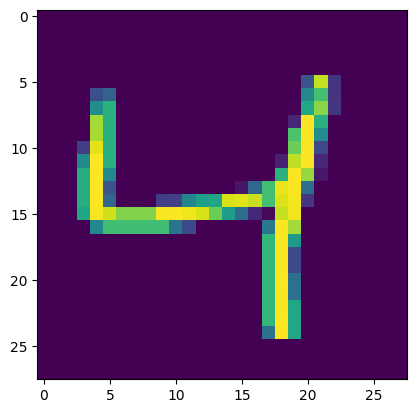

In [ ]:
#The usual preamble
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf


#load the handwriting MNIST database
from keras.datasets import mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()
plt.imshow(x_train[2,:,:])
x = x_train[2,:,:]
im_height,im_width=x.shape
x.shape

In [ ]:
from re import A
#create noisy sample images
n_images = 10
n_samples_per_image = 100
n_total_samples = n_images * n_samples_per_image
im_orig = np.zeros((n_total_samples,im_height,im_width,1))  #1 at the end is for a single color channel
im_noisy = np.zeros((n_total_samples,im_height,im_width,1))
im_index = 0
for im in range(n_images):
  x = x_train[im,:,:]
  xf = x.astype(float)
  xf /= np.max(xf)
  for j in range(n_samples_per_image):
    xf1 = xf + np.random.rand(im_height,im_width)*np.max(xf)
    xf1 /= np.max(xf1)
    xf1[xf1<0] = 0
    xf1[xf1>1] = 1
    im_noisy[im_index,:,:,0] = xf1
    im_orig[im_index,:,:,0] = xf
    im_index = im_index+1



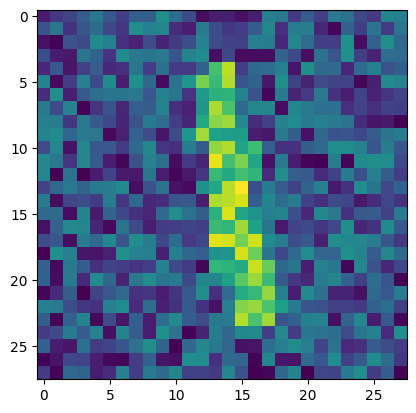

In [ ]:
#randomize order of images, but use same order for original and noisy images.
rand_idx = list(range(im_index))
np.random.shuffle(rand_idx)
im_orig = im_orig[rand_idx,:,:,:]
im_noisy = im_noisy[rand_idx,:,:,:]

plt.imshow(im_noisy[1,:,:])

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping
early_stop = EarlyStopping(monitor='val_loss',patience=3)

In [ ]:
#build the network
from tensorflow.python.keras.engine.base_layer_utils import uses_keras_history
from tensorflow.keras.utils import plot_model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Reshape, Conv2D, Reshape, LayerNormalization, BatchNormalization, TimeDistributed
from tensorflow.keras.layers import MaxPooling2D, GlobalAveragePooling2D  #useful for combining the outputs of convolution layers

len_conv_window = 5           #how many points in the convolution kernel in both x and y directions
n_conv_units = 1              #how many different convolution kernels h_i
n_sensors = 1                  #3 colors at each point.   could be multi-spectral, sensors, etc.

model = Sequential()
model.add(Conv2D(filters = n_conv_units,
                kernel_size = (len_conv_window, len_conv_window),  #these are the spatial filter kernels
                activation = 'linear',
                input_shape = (im_height, im_width, n_sensors),  #use when predict_length=1, batch_size=1
                padding = 'same'))

model.compile(optimizer='adam', loss='mse')
model.summary()



Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 28, 28, 1)         26        
                                                                 
Total params: 26 (104.00 Byte)
Trainable params: 26 (104.00 Byte)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


Epoch 1/10
113/113 [==============================] - 1s 5ms/step - loss: 0.1520 - val_loss: 0.1104
Epoch 2/10
113/113 [==============================] - 0s 4ms/step - loss: 0.0976 - val_loss: 0.0853
Epoch 3/10
113/113 [==============================] - 0s 4ms/step - loss: 0.0752 - val_loss: 0.0656
Epoch 4/10
113/113 [==============================] - 0s 4ms/step - loss: 0.0586 - val_loss: 0.0516
Epoch 5/10
113/113 [==============================] - 0s 4ms/step - loss: 0.0468 - val_loss: 0.0417
Epoch 6/10
113/113 [==============================] - 0s 4ms/step - loss: 0.0385 - val_loss: 0.0348
Epoch 7/10
113/113 [==============================] - 0s 4ms/step - loss: 0.0325 - val_loss: 0.0298
Epoch 8/10
113/113 [==============================] - 0s 4ms/step - loss: 0.0283 - val_loss: 0.0262
Epoch 9/10
113/113 [==============================] - 0s 4ms/step - loss: 0.0253 - val_loss: 0.0237
Epoch 10/10
113/113 [==============================] - 0s 4ms/step - loss: 0.0231 - val_loss: 0.0220

<Axes: >

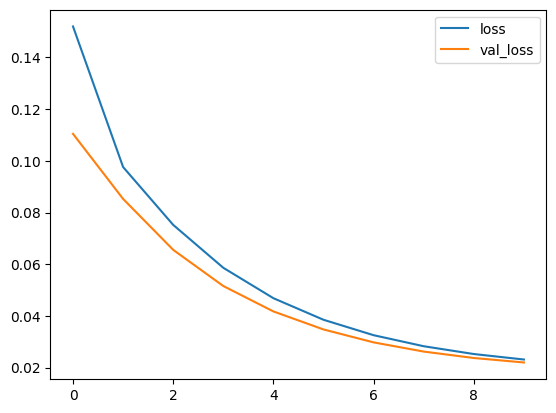

In [ ]:
model.fit(im_noisy,im_orig,epochs=10, batch_size=8, validation_split=0.1, callbacks=[early_stop])
losses = pd.DataFrame(model.history.history)
losses.plot()

In [ ]:
im_predict = model.predict(im_noisy)
im_predict.shape

32/32 [==============================] - 0s 2ms/step


(1000, 28, 28, 1)

TensorShape([5, 5, 1, 1])

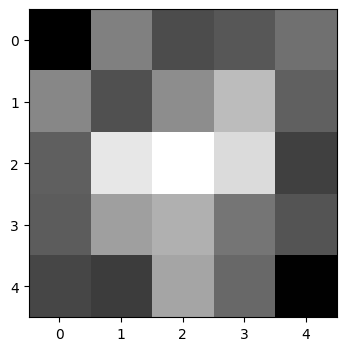

In [ ]:

plt.figure(figsize=(4,4))
plt.imshow(model.weights[0][:,:,0,0], cmap=plt.get_cmap('gray'));
model.weights[0].shape

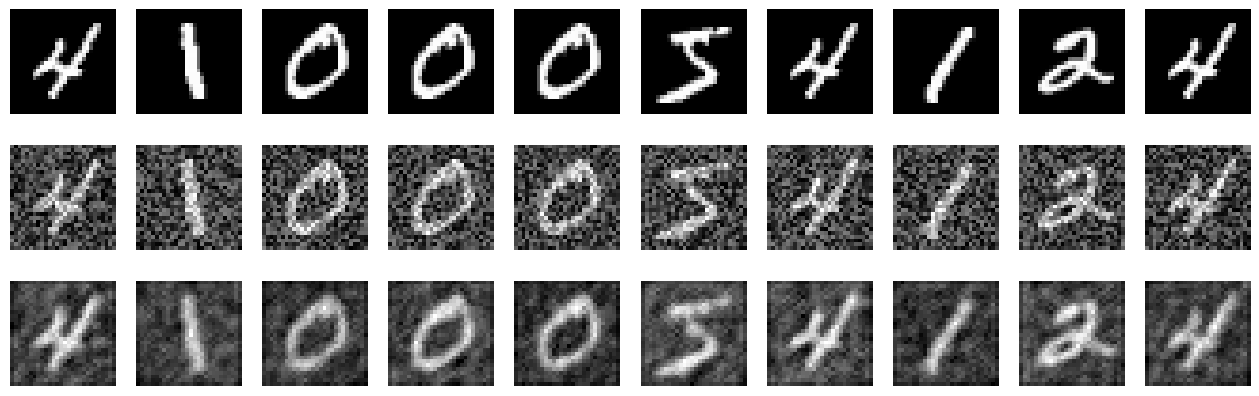

In [ ]:
#model.weights[0] # dimensions 5x5 = width x height x sensors x outputs
#show the filter results
plt.figure(figsize=(16,5))
for n in range(10):
  ax = plt.subplot(3,10,n+1)
  plt.imshow(im_orig[n,:,:], cmap=plt.get_cmap('gray'));
  ax.axis('off')
  ax = plt.subplot(3,10,n+11)
  plt.imshow(im_noisy[n,:,:], cmap=plt.get_cmap('gray'));
  ax.axis('off')
  ax = plt.subplot(3,10,n+21)
  plt.imshow(im_predict[n,:,:], cmap=plt.get_cmap('gray'));
  ax.axis('off')

In [ ]:
#build the network for a nonlinear noise reduction filter
from tensorflow.python.keras.engine.base_layer_utils import uses_keras_history
from tensorflow.keras.utils import plot_model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Reshape, Conv2D, Reshape, LayerNormalization, BatchNormalization
from tensorflow.keras.layers import MaxPooling2D, GlobalAveragePooling2D  #useful for combining the outputs of convolution layers

len_conv_window = 5           #how many points in the convolution kernel in both x and y directions
n_conv_units = 10            #how many different convolution kernels h_i
n_conv_units_output = 1
n_sensors = 1                  #3 colors at each point.   could be multi-spectral, sensors, etc.

model2 = Sequential()
#first layer creates a 20 5x5 spatial filters and convolves each with the input
#need to specify input shape for the first layer only
model2.add(Conv2D(filters = n_conv_units,
                kernel_size = (len_conv_window, len_conv_window),  #these are the spatial filter kernels
                activation = 'tanh',
                input_shape = (im_height, im_width, n_sensors),  #use when predict_length=1, batch_size=1
                padding = 'same'))
model2.add(Conv2D(filters = n_conv_units,
                kernel_size = (len_conv_window, len_conv_window),  #these are the spatial filter kernels
                activation = 'tanh',
                padding = 'same'))
model2.add(Conv2D(filters = n_conv_units_output,
                kernel_size = (len_conv_window, len_conv_window),  #these are the spatial filter kernels
                activation = 'linear',
                padding = 'same'))

model2.compile(optimizer='adam', loss='mse')
model2.summary()



Model: "sequential_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_15 (Conv2D)          (None, 28, 28, 10)        260       
                                                                 
 conv2d_16 (Conv2D)          (None, 28, 28, 10)        2510      
                                                                 
 conv2d_17 (Conv2D)          (None, 28, 28, 1)         251       
                                                                 
Total params: 3021 (11.80 KB)
Trainable params: 3021 (11.80 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


Epoch 1/25
113/113 [==============================] - 2s 10ms/step - loss: 0.0342 - val_loss: 0.0173
Epoch 2/25
113/113 [==============================] - 1s 8ms/step - loss: 0.0168 - val_loss: 0.0162
Epoch 3/25
113/113 [==============================] - 1s 8ms/step - loss: 0.0163 - val_loss: 0.0161
Epoch 4/25
113/113 [==============================] - 1s 8ms/step - loss: 0.0161 - val_loss: 0.0159
Epoch 5/25
113/113 [==============================] - 1s 8ms/step - loss: 0.0161 - val_loss: 0.0157
Epoch 6/25
113/113 [==============================] - 1s 8ms/step - loss: 0.0158 - val_loss: 0.0156
Epoch 7/25
113/113 [==============================] - 1s 8ms/step - loss: 0.0158 - val_loss: 0.0157
Epoch 8/25
113/113 [==============================] - 1s 8ms/step - loss: 0.0157 - val_loss: 0.0156
Epoch 9/25
113/113 [==============================] - 1s 8ms/step - loss: 0.0156 - val_loss: 0.0154
Epoch 10/25
113/113 [==============================] - 1s 8ms/step - loss: 0.0156 - val_loss: 0.015

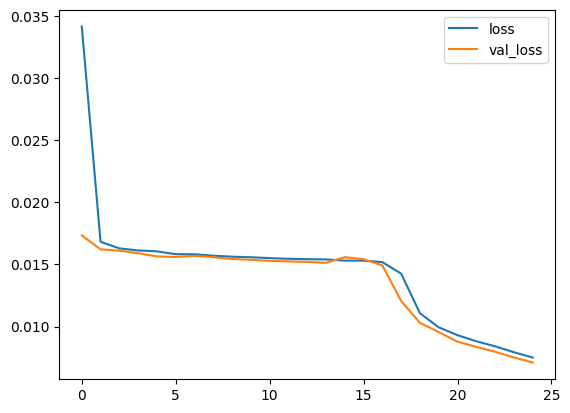

In [ ]:
model2.fit(im_noisy,im_orig,epochs=25, batch_size=8, validation_split=0.1, callbacks=[early_stop])
losses = pd.DataFrame(model2.history.history)
losses.plot()
im_predict = model2.predict(im_noisy)


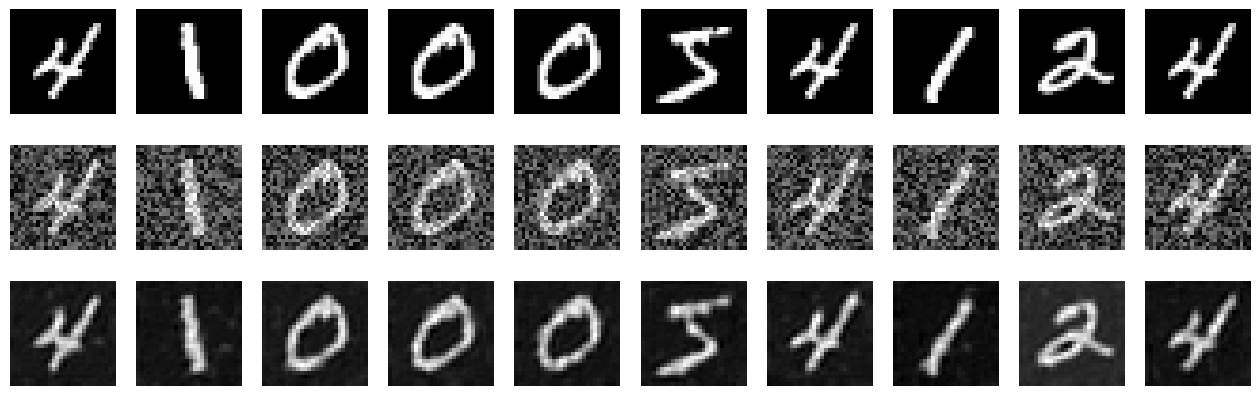

In [ ]:
#show the filter results
plt.figure(figsize=(16,5))
for n in range(10):
  ax = plt.subplot(3,10,n+1)
  plt.imshow(im_orig[n,:,:], cmap=plt.get_cmap('gray'));
  ax.axis('off')
  ax = plt.subplot(3,10,n+11)
  plt.imshow(im_noisy[n,:,:], cmap=plt.get_cmap('gray'));
  ax.axis('off')
  ax = plt.subplot(3,10,n+21)
  plt.imshow(im_predict[n,:,:], cmap=plt.get_cmap('gray'));
  ax.axis('off')

In [ ]:
## vestibular-ocular reflex in humans
from matplotlib.dates import DateFormatter
import cv2
#from moviepy.editor import *
'pip install imageio-ffmpeg'

#for your homework
np.random.seed(10327798)
tf.random.set_seed(10327798)


In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
video_filename = '/content/drive/MyDrive/Colab Notebooks/CHOCVideo2.mov'. ## this is the df/dx
video_reader = cv2.VideoCapture(video_filename)


Width = 640, Height = 360, Colors = 3


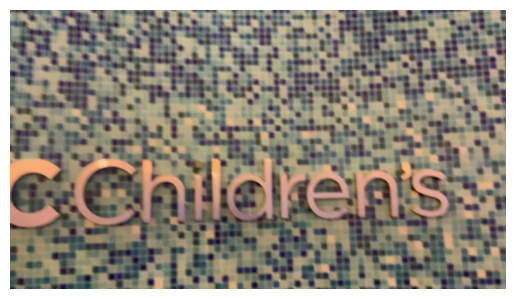

In [ ]:
_, bgr_frame = video_reader.read()
rgb_frame = cv2.cvtColor(bgr_frame, cv2.COLOR_BGR2RGB)  #convert to RGB order for processing
plt.imshow(rgb_frame)
plt.axis('off')
orig_width = bgr_frame.shape[1]
orig_height = bgr_frame.shape[0]
ncolors = bgr_frame.shape[2]
image_width = 128
image_height = int(orig_height * image_width / orig_width)  #proportional scaling to preserve aspect ratio
print(f'Width = {orig_width}, Height = {orig_height}, Colors = {ncolors}')


In [ ]:
frames_list = []
nframes = 0
while True:
  success, bgr_frame = video_reader.read()
  if not success:
    break
  rgb_frame = cv2.cvtColor(bgr_frame, cv2.COLOR_BGR2RGB)   #RGB color conversion
  resized_frame = cv2.resize(rgb_frame, (image_width, image_height))  #resize and smooth to make smaller
  normalized_frame = resized_frame / 255
  if nframes > 0:
    last_frame = np.append(last_frame, normalized_frame, axis=2)   #append along the color axis to make a double frame
    frames_list.append(last_frame)
    last_frame = normalized_frame.copy()
  if nframes == 0:
    last_frame = normalized_frame.copy()
  nframes +=1
video_reader.release()
print(f'Read {nframes} frames')


Read 1846 frames


(72, 128, 6)

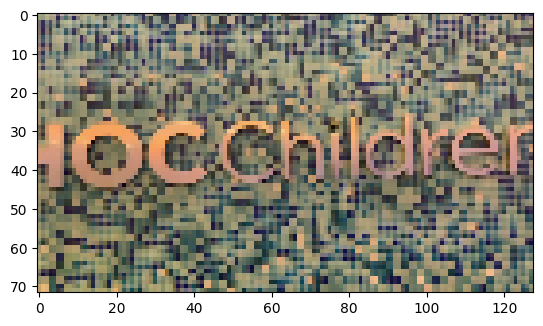

In [ ]:
plt.figure()
plt.imshow(frames_list[200][:,:,0:3]);   #note that to display we need to select one of the two images 0:3 or 3:6
frames_list[200].shape

In [ ]:
dfGyro = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/gyro.csv')
dfGyro = dfGyro.rename(columns={
    'Time' : 't',
    ' Rotation Rate (X)' : 'wx',
    ' Rotation Rate (Y)' : "wy",
    ' Rotation Rate (Z)' : "wz"})   #data record at 30Hz, which is same as video frame rate
dfGyro['t'] = dfGyro['t'] - dfGyro['t'][0]  #set the initial time to be zero
dfGyro

,t,wx,wy,wz
0,0.00000,0.099509,-0.028426,-0.044815
1,0.03334,-0.003392,0.011171,-0.077364
2,0.06667,0.095900,-0.036499,-0.057394
3,0.10000,0.339899,-0.068623,0.027582
4,0.13334,0.290086,0.027662,0.018464
...,...,...,...,...
1832,61.05606,0.019010,0.038634,-0.068281
1833,61.08941,0.092307,-0.020316,0.006578
1834,61.12276,0.033317,-0.014301,0.038383
1835,61.15614,-0.001969,-0.004178,-0.023021


(1800, 2)

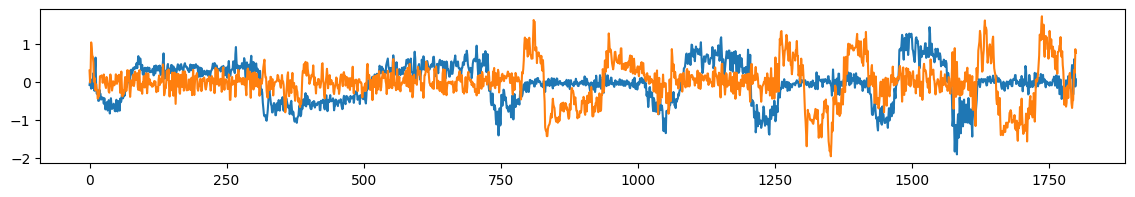

In [ ]:
#predict both the horizontal and vertical gyro
desired_output_horizontal = dfGyro['wy'] / (2*dfGyro['wy'].std())   #normalize so the network can learn
desired_output_vertical = dfGyro['wx'] / (2*dfGyro['wx'].std())
desired_output = np.vstack((desired_output_horizontal.values, desired_output_vertical.values)).transpose()  #make column-wise
nTimes = 1800
desired_output = desired_output[:nTimes,:]

#make a list of the video frames that has the timestamps
nTimes, nOutputs = desired_output.shape  #in this case, the gyro data is slightly shorter than the video data
frames_list = frames_list[:nTimes]       #trim the video to be exactly the length of the gyro
      #to be safe, I checked first that the video length and gyro data length were the same; never trust the stated frame rate
imSeries = pd.Series(data=frames_list, index=dfGyro['t'][:nTimes])   #assigns timestamps to the video data in case we need that
framesL = np.asarray(frames_list)  #will need later for numpy array to feed to the network

plt.figure(figsize=(14,2))
plt.plot(desired_output);   #the gyro data are quite noisy.  I don't bother filtering it; the network has to figure this out.
desired_output.shape


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping
early_stop = EarlyStopping(monitor='val_loss',patience=3)

In [ ]:
#compare to the raw frames that go into this
framesL.shape

(1800, 72, 128, 6)

In [ ]:
#build the network to predict image motion from pairs of frames
from tensorflow.python.keras.engine.base_layer_utils import uses_keras_history
from tensorflow.keras.utils import plot_model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Reshape, Conv2D, Reshape, LayerNormalization, BatchNormalization
from tensorflow.keras.layers import MaxPooling2D, GlobalAveragePooling2D  #useful for combining the outputs of convolution layers

len_conv_window = 7            #how many points in the convolution kernel in both x and y directions
n_conv_units = 40              #how many different convolution kernels h_i
n_conv_units2 = 20              #how many different convolution kernels h_i
n_sensors = 3                  #3 colors at each point.   could be multi-spectral, sensors, etc.
n_time_images = 2


model3 = Sequential()
# layer creates 40 7x7 spatial filters and convolves each with the input
#model3.add(Reshape((image_height, image_width, n_sensors*n_time_images))) #needed to remove predict_length dimension
model3.add(Conv2D(filters = n_conv_units,
                kernel_size = (len_conv_window, len_conv_window),  #these are the spatial filter kernels
                activation = 'tanh',
                padding = 'same',
                input_shape = (image_height, image_width, n_sensors*n_time_images),
                data_format="channels_last"))
model3.add(Conv2D(filters = n_conv_units,
                kernel_size = (len_conv_window, len_conv_window),  #these are the spatial filter kernels
                activation = 'tanh',
                padding = 'same',
                data_format="channels_last"))
#second layer creates nonlinear combinations of the 20 spatial filters at each point to create a nonlinear basis
model3.add(Conv2D(filters = n_conv_units2,
                kernel_size = (1, 1),     #computation at each pixel location
                activation = 'tanh',
                padding = 'same',
                data_format="channels_last"))
#third layer gives more nonlinearity at each pixel
model3.add(Conv2D(filters = n_conv_units2,
                kernel_size = (1, 1),     #computation at each pixel location
                activation = 'tanh',
                padding = 'same',
                data_format="channels_last"))
#fourth layer estimates the local optic flow
model3.add(Conv2D(filters = nOutputs,             #just two outputs, so we get vx and vy
                kernel_size = (1, 1),     #computation at each pixel location
                activation = 'tanh',
                padding = 'same',
                data_format="channels_last"))

#pooling layer says that we want to take the average of the local velocities  E[vx], E[vy]
model3.add(GlobalAveragePooling2D())  #averages over everything but the last input dimension
model3.add(BatchNormalization(axis=-1 , center=True , scale=True))  #average has low power.  this increases power into a good range for learning
  #Note: BatchNormalization normalizes over the batch, so you need BatchSize = 32 or something
  #Alternative is LayerNormalization, but this layer only has 2 elements.
model3.add(Dense(nOutputs))  #to get the output scaling right

opt = tf.optimizers.Adam(learning_rate=0.0005)
model3.compile(optimizer=opt, loss='mse')
model3.summary()


Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_4 (Conv2D)           (None, 72, 128, 40)       11800     
                                                                 
 conv2d_5 (Conv2D)           (None, 72, 128, 40)       78440     
                                                                 
 conv2d_6 (Conv2D)           (None, 72, 128, 20)       820       
                                                                 
 conv2d_7 (Conv2D)           (None, 72, 128, 20)       420       
                                                                 
 conv2d_8 (Conv2D)           (None, 72, 128, 2)        42        
                                                                 
 global_average_pooling2d (  (None, 2)                 0         
 GlobalAveragePooling2D)                                         
                                                      

Epoch 1/5
107/107 [==============================] - 38s 342ms/step - loss: 0.1547 - val_loss: 0.3234
Epoch 2/5
107/107 [==============================] - 36s 338ms/step - loss: 0.1107 - val_loss: 0.4363
Epoch 3/5
107/107 [==============================] - 36s 336ms/step - loss: 0.0997 - val_loss: 0.3963
Epoch 4/5
107/107 [==============================] - 36s 336ms/step - loss: 0.0986 - val_loss: 0.3467


<Axes: >

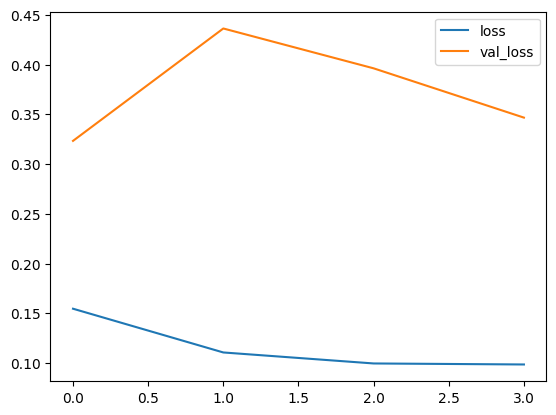

In [ ]:
model3.fit(framesL, desired_output,epochs=5, batch_size=16, validation_split=0.05, callbacks=[early_stop])
losses = pd.DataFrame(model3.history.history)
losses.plot()

In [ ]:
predicted_output = model3.predict(framesL) #(generator)
#dfPredict = pd.DataFrame(data=predicted_output)
#nPredict,_  = dfPredict.shape

57/57 [==============================] - 3s 43ms/step


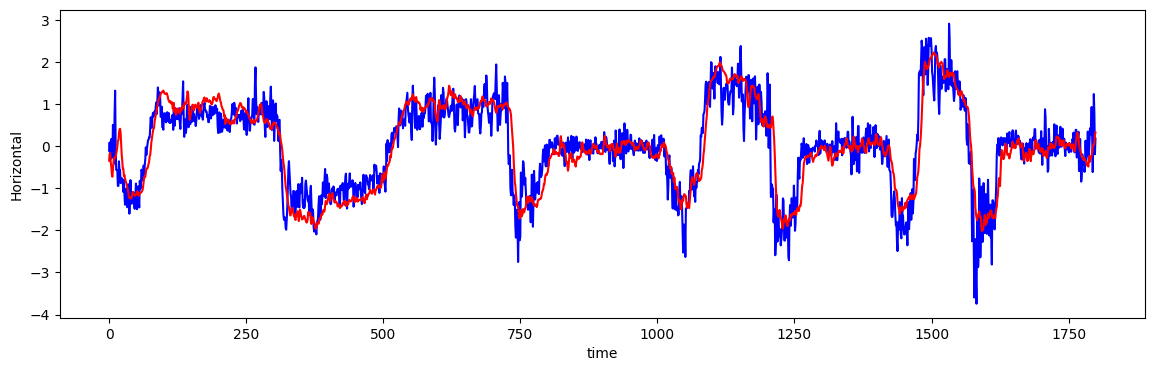

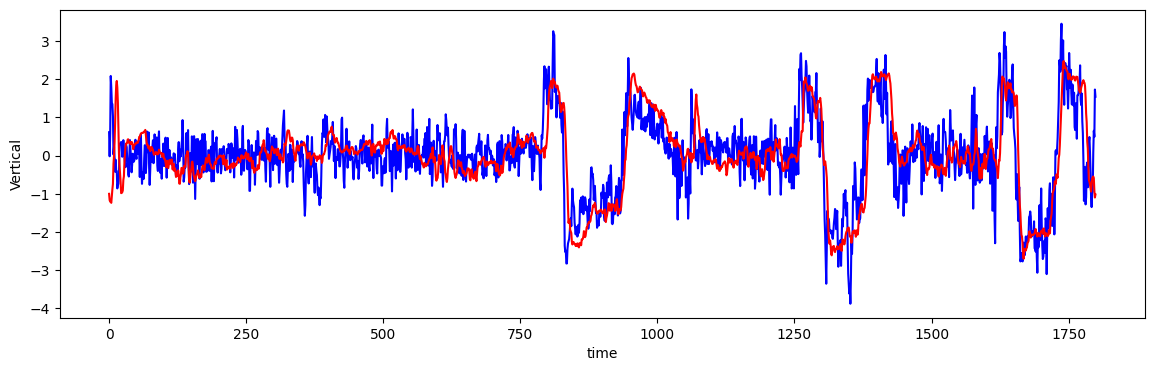

In [ ]:
#predict = dfPredict.values.copy()   #do not have to do ML or MMSE calculation here
predict = predicted_output
desired = desired_output

#put at the same scale
predict = predict - predict.mean(axis=0)   #subtract the mean
predict /= predict.std(axis=0)    #should not have to do this
desired = desired - desired.mean(axis=0)
desired /= desired.std(axis=0)

plt.figure(figsize=(14,4),linewidth=.1)
plt.plot(desired[:,0],'b')  #compare one column at a time
plt.plot(predict[:,0],'r')
plt.ylabel('Horizontal')
plt.xlabel('time');

plt.figure(figsize=(14,4),linewidth=.1)
plt.plot(desired[:,1],'b')  #compare one column at a time
plt.plot(predict[:,1],'r')
plt.ylabel('Vertical')
plt.xlabel('time');




In [ ]:
model3.weights[0].shape

TensorShape([7, 7, 6, 40])

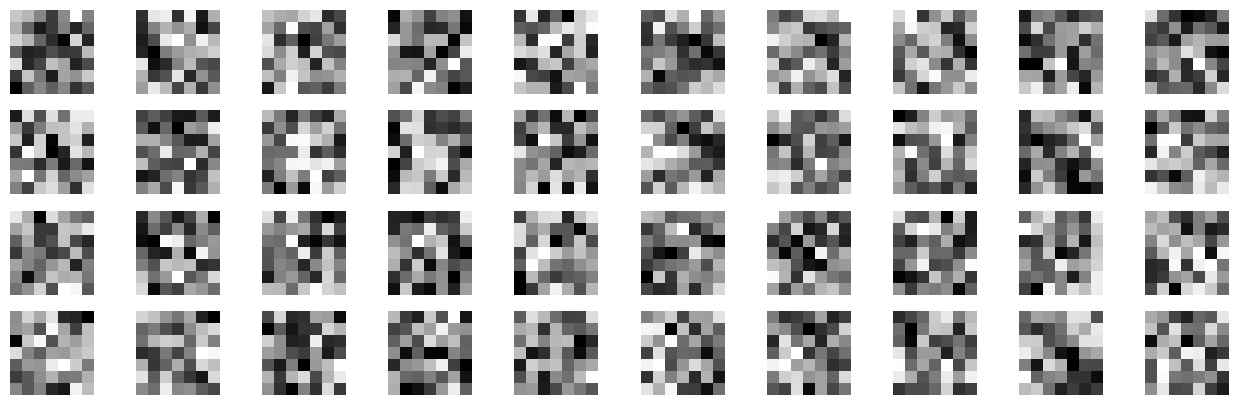

In [ ]:
#model.weights[0] # dimensions 5x5x6x40 = width x height x sensors x outputs
plt.figure(figsize=(16,5))
for n in range(40):
  ax = plt.subplot(4,10,n+1)
  plt.imshow(model3.weights[0][:,:,0,n], cmap=plt.get_cmap('gray'));
  ax.axis('off')

In [ ]:
rms_error = np.sqrt(np.sum(np.mean(np.square(predict-desired))))
print('Scalar output rms_error {}'.format(rms_error));

Scalar output rms_error 0.6263281073949937
